# Chapter 37 - From Average Return to the Next Pound

Chapter 36 ended with the calibrated Sedge Shoes model and a table of average returns.
This notebook asks the question Chapter 37 asks: not "was this channel worth what we spent on it", the average-return question, but "what would the next pound buy", the marginal-return question, and shows that the two do not have to agree.
Every number comes from the calibrated case-study model, draw by draw, so the uncertainty in each curve's shape reaches the marginal returns.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mmm_book import RANDOM_SEED
from mmm_book.case_model import (
    fit_case_model,
    marginal_roas_draws,
    posterior_curves,
    prepare_case_data,
    roas_table,
)
from mmm_book.plotting import mmm_style
from mmm_book.sedge import (
    CHANNELS,
    GROUND_TRUTH,
    correct_distribution,
    generate_sedge,
    true_marginal_roas,
)

mmm_style()
pd.set_option("display.width", 120)
BREAK_EVEN = 2.0  # a 50 per cent contribution margin
fixed = correct_distribution(generate_sedge(seed=RANDOM_SEED))
data = prepare_case_data(fixed, "model2")
idata = fit_case_model(fixed, "model2", calibrate=True)
print(f"divergent transitions: {int(idata.sample_stats['diverging'].sum())}")

divergent transitions: 0


## Average and marginal return, draw by draw

`marginal_roas_draws` raises each channel's spend by 1 per cent in every region and week, pushes it through each posterior draw's own adstock and saturation, and divides the extra revenue by the extra spend.
The average return is each draw's ROAS.

In [2]:
avg = roas_table(idata, data)
marg = marginal_roas_draws(idata, data)
rows = {}
for ch in CHANNELS:
    m = marg[ch]
    rows[ch] = {
        "average": avg.loc[ch, "roas_mean"],
        "avg 5%": avg.loc[ch, "roas_lo"],
        "avg 95%": avg.loc[ch, "roas_hi"],
        "marginal": m.mean(),
        "marg 5%": np.quantile(m, 0.05),
        "marg 95%": np.quantile(m, 0.95),
        "P(marginal > 2.0)": (m > BREAK_EVEN).mean(),
    }
table = pd.DataFrame(rows).T
print(table.round(3))
print(f"\nranked by average:  {list(table['average'].sort_values(ascending=False).index)}")
print(f"ranked by marginal: {list(table['marginal'].sort_values(ascending=False).index)}")

         average  avg 5%  avg 95%  marginal  marg 5%  marg 95%  P(marginal > 2.0)
tv         2.568   2.404    2.737     2.220    2.111     2.328              1.000
search     2.218   1.707    2.772     1.393    1.018     1.778              0.006
meta       1.652   1.045    2.357     1.112    0.643     1.580              0.000
youtube    2.200   1.242    3.272     1.871    1.037     2.744              0.395
ooh        1.652   1.159    2.285     1.394    1.028     1.782              0.006

ranked by average:  ['tv', 'search', 'youtube', 'meta', 'ooh']
ranked by marginal: ['tv', 'youtube', 'ooh', 'search', 'meta']


Television leads on both measures.
Search and YouTube are level on average and far apart at the margin, because Search is deep into its curve while YouTube still has room.
Meta's next pound returns about £1.10, well below the £2 it needs at Sedge's 50 per cent margin, although its average is comfortably above one.
Only Television's next pound clears the 2.0 break-even with confidence; YouTube's does so in about four draws in ten.

## The response curves, with their uncertainty

`posterior_curves` builds one curve per posterior draw from that draw's own parameters.
A budget change scales the channel's whole historical plan, so Television keeps its flighting around the spring races and Christmas at any budget level.

tv       marginal from the curves 2.22
search   marginal from the curves 1.39
meta     marginal from the curves 1.12
youtube  marginal from the curves 1.86
ooh      marginal from the curves 1.39


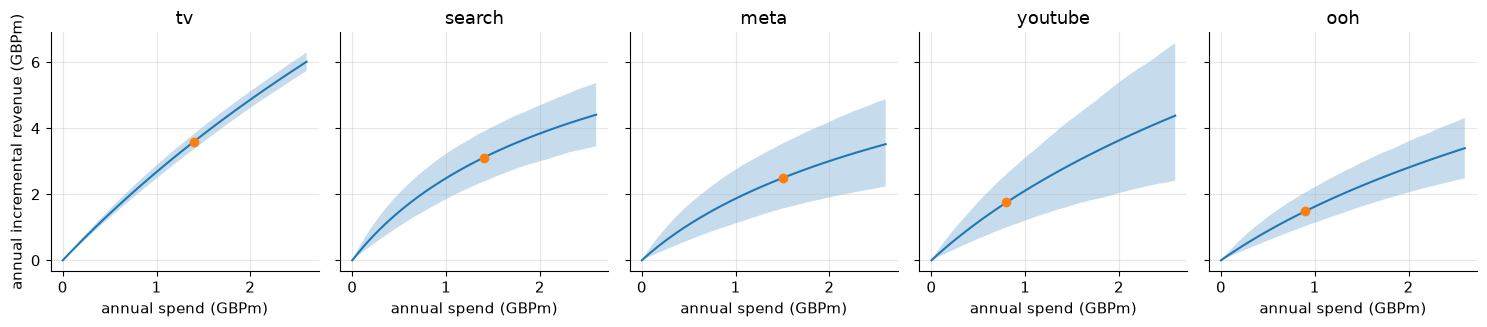

In [3]:
curves = posterior_curves(idata, data)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharey=True)
for ax, ch in zip(axes, CHANNELS, strict=True):
    grid = np.linspace(0.0, 2.6e6, 66)
    draws = np.array([curves.draws(ch, x / 52) for x in grid]) * 52 / 1e6
    lo, hi = np.quantile(draws, [0.05, 0.95], axis=1)
    ax.fill_between(grid / 1e6, lo, hi, alpha=0.25)
    ax.plot(grid / 1e6, draws.mean(axis=1))
    cur = curves.current_money[ch] * 52
    ax.plot([cur / 1e6], [curves.money_contribution(ch, cur / 52) * 52 / 1e6], "o")
    ax.set_title(ch)
    ax.set_xlabel("annual spend (GBPm)")
axes[0].set_ylabel("annual incremental revenue (GBPm)")
fig.tight_layout()
for ch in CHANNELS:
    print(f"{ch:<8} marginal from the curves {curves.marginal_return(ch):.2f}")

## The profit lens

At a 50 per cent contribution margin, revenue becomes margin and spend is subtracted.

In [4]:
spend = pd.Series({ch: data.annual_spend(ch) / 1e6 for ch in CHANNELS})
revenue = avg["annual_contribution_m"]
lens = pd.DataFrame(
    {"revenue": revenue, "margin": 0.5 * revenue, "spend": spend, "profit": 0.5 * revenue - spend}
)
lens["profit ROI"] = lens["profit"] / lens["spend"]
lens.loc["total"] = lens.sum()
lens.loc["total", "profit ROI"] = lens.loc["total", "profit"] / lens.loc["total", "spend"]
print(lens.round(3))

         revenue  margin  spend  profit  profit ROI
tv         3.596   1.798    1.4   0.398       0.284
search     3.105   1.553    1.4   0.153       0.109
meta       2.479   1.239    1.5  -0.261      -0.174
youtube    1.760   0.880    0.8   0.080       0.100
ooh        1.487   0.743    0.9  -0.157      -0.174
total     12.427   6.213    6.0   0.213       0.036


## Against the truth

The true average and marginal returns the generator built in, beside the fit (Appendix F of the book prints this comparison).

In [5]:
truth_marg = true_marginal_roas()
check = pd.DataFrame(
    {
        "average fit": table["average"],
        "average truth": pd.Series(GROUND_TRUTH),
        "marginal fit": table["marginal"],
        "marg 5%": table["marg 5%"],
        "marg 95%": table["marg 95%"],
        "marginal truth": pd.Series(truth_marg),
    }
)
print(check.round(2))

         average fit  average truth  marginal fit  marg 5%  marg 95%  marginal truth
tv              2.57           2.40          2.22     2.11      2.33            2.10
search          2.22           2.70          1.39     1.02      1.78            1.40
meta            1.65           1.75          1.11     0.64      1.58            0.90
youtube         2.20           2.00          1.87     1.04      2.74            1.80
ooh             1.65           1.50          1.39     1.03      1.78            1.47


Four of the five marginal intervals contain the truth; Television's lower end, 2.11, sits just above the true 2.10.
The ranking at the margin (Television first, YouTube second, Meta last) is the same in the fit and the truth; Meta's next pound is the one the model overstates most.

## Takeaway

Average return answers whether a channel was worth what has already been spent on it.
Marginal return answers what the next pound would buy, at the spend level a budget decision would change, and it is the number that should drive a decision to spend more or less.
Read both with their intervals: a marginal return is read off the shape of a curve, which the data pin down less firmly than its height.